# Assignment 1 AI Model Development for Malware Detection

Dataset: CIC-MalMem-2022. Model: Decision Tree Classifier. Split: 80:20.


## 1 Import libraries


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error, mean_squared_error,
                             confusion_matrix, roc_auc_score, roc_curve)
RANDOM_STATE = 42


## 2 Load and understand the dataset


In [2]:
df = pd.read_csv('../data/Obfuscated-MalMem2022.csv')
print('Shape:', df.shape)
print(df['Class'].value_counts())
df.head()


Shape: (58596, 57)
Class
Benign     29298
Malware    29298


## 3 Pre-process the data


In [3]:
df.columns = df.columns.str.strip()
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates().copy()
y = df['Class'].map({'Benign': 0, 'Malware': 1}).astype('int8')
X = df.drop(columns=['Class', 'Category'], errors='ignore')
constant_cols = [c for c in X if X[c].nunique(dropna=False) <= 1]
X = X.drop(columns=constant_cols)
print('Clean shape:', X.shape)
print('Constant columns removed:', constant_cols)


Clean shape: (58062, 52)
Constant columns removed: ['pslist.nprocs64bit', 'handles.nport', 'svcscan.interactive_process_services']


## 4 Split, select the top 10 features and train the model


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_classif, k=10)),
    ('classifier', DecisionTreeClassifier(max_depth=8,
         min_samples_leaf=2, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
selected = X_train.columns[model.named_steps['selector'].get_support()]
print(selected.tolist())


pslist.avg_threads
dlllist.ndlls
dlllist.avg_dlls_per_proc
handles.nevent
handles.nthread
handles.ntimer
handles.nsection
handles.nmutant
ldrmodules.not_in_load
ldrmodules.not_in_mem


## 5 Evaluate the model


In [5]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]
print('Accuracy :', accuracy_score(y_test, y_pred))
print('Precision:', precision_score(y_test, y_pred))
print('Recall   :', recall_score(y_test, y_pred))
print('F1 score :', f1_score(y_test, y_pred))
print('MAE      :', mean_absolute_error(y_test, y_pred))
print('MSE      :', mean_squared_error(y_test, y_pred))
print('ROC-AUC  :', roc_auc_score(y_test, y_prob))
print(confusion_matrix(y_test, y_pred))


Accuracy : 0.9987083441
Precision: 0.9991320951
Recall   : 0.9982656955
F1 score : 0.9986987074
MAE      : 0.0012916559
MSE      : 0.0012916559
ROC-AUC  : 0.9994336889
[[5842, 5], [10, 5756]]


## 6 Plot the ROC curve


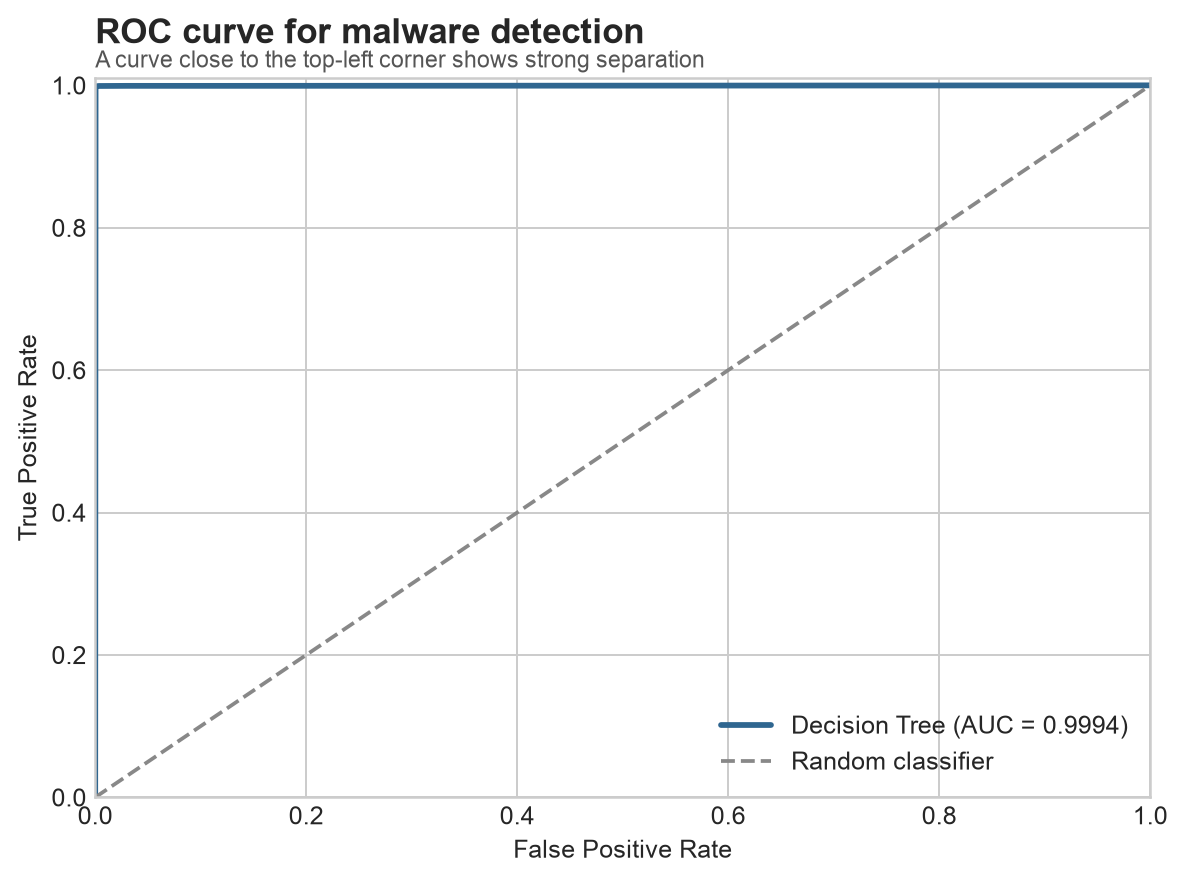

In [6]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_prob):.4f}')
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(); plt.show()


## 7 Make sample predictions


In [7]:
sample = X_test.iloc[:10]
result = pd.DataFrame({
    'Actual': y_test.iloc[:10].map({0:'Benign', 1:'Malware'}).values,
    'Predicted': pd.Series(model.predict(sample)).map({0:'Benign', 1:'Malware'}),
    'Malware probability': model.predict_proba(sample)[:, 1]
})
result


The first 10 sample predictions are shown in the report and saved in sample_predictions.csv.


## Conclusion

The Decision Tree detected malware with 99.87% accuracy on the held-out test set. A separate malware-family or external test set is recommended before real deployment.
